# MLIP Studio Python API — Google Colab showcase

This notebook installs MLIP Studio using the same custom dependency order documented in the repository, clones the source, installs the API with `--no-deps`, and demonstrates every currently public task API.

Before running it, select **Runtime → Change runtime type → T4 GPU** (or another GPU). NOTE: Use runtime version 2025.10.

**Python version:** MLIP Studio has only been tested with Python versions up to **3.12.12**. Newer Python versions have not been tested. The first code cell prints the Python version of your runtime.

The full model stack is large and installation/model downloads can take a while. UMA/eSEN may require prior Hugging Face license approval and login. Individual gated-model sections catch access errors so the rest of the notebook can still run.

Model predictions are examples, not reference-quality scientific results. Always choose a model trained for the relevant chemical/material domain and review its license and citation.

In [28]:
import platform
import shutil
import subprocess
import sys

print("Python:", sys.version)
print("Platform:", platform.platform())
if shutil.which("nvidia-smi"):
    subprocess.run(["nvidia-smi"], check=False)
else:
    print("No NVIDIA GPU detected. The examples will use CPU and may be slow.")

Python: 3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.35


## 1. Clone MLIP Studio

In [29]:
from pathlib import Path
import subprocess

REPO_URL = "https://github.com/mlipstudio/MLIP-Studio.git"
if Path("/kaggle/working").is_dir():
    RUNTIME_DIR = Path("/kaggle/working")
elif Path("/content").is_dir():
    RUNTIME_DIR = Path("/content")
else:
    RUNTIME_DIR = Path.cwd()
REPO_DIR = RUNTIME_DIR / "MLIP-Studio"

if not REPO_DIR.exists():
    subprocess.run(
        ["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)],
        check=True,
    )
else:
    print(f"Using existing checkout: {REPO_DIR}")

print("Repository:", REPO_DIR)

Using existing checkout: /content/MLIP-Studio
Repository: /content/MLIP-Studio


## 2. Install system and Python dependencies

These commands intentionally mirror the README/Docker installation order. Several packages are installed with `--no-deps` because their upstream dependency metadata conflicts with the combined MLIP environment. The last command installs the optional `aimnet==0.0.1` package used by the AIMNet2 section.

> **Colab may ask you to restart the session.** During or after the installation, Google Colab often shows a pop-up recommending that you restart the session. Click **Cancel** and continue running the notebook from the next cell. If you restart by accident, run the cells again from the top.

In [30]:
!apt-get -qq update
!apt-get -qq install -y build-essential git swig libopenbabel-dev openbabel

W: An error occurred during the signature verification. The repository is not updated and the previous index files will be used. GPG error: https://cli.github.com/packages stable InRelease: The following signatures couldn't be verified because the public key is not available: NO_PUBKEY 5612B36462313325
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
W: Failed to fetch https://cli.github.com/packages/dists/stable/InRelease  The following signatures couldn't be verified because the public key is not available: NO_PUBKEY 5612B36462313325
W: Some index files failed to download. They have been ignored, or old ones used instead.


In [31]:
%pip install --upgrade pip
%pip install --no-deps fairchem-core==2.16.0 --ignore-requires-python
requirements_file = str(REPO_DIR / "requirements.txt")
%pip install -r "$requirements_file"
%pip install --no-deps "upet@git+https://github.com/lab-cosmo/upet.git" --ignore-requires-python
%pip install --no-deps "git+https://github.com/WillBaldwin0/graph_electrostatics.git@v0.4.0" --ignore-requires-python
# Optional: AIMNet2 models (section 8)
%pip install --no-deps aimnet==0.0.1

  Cloning https://github.com/manassharma07/mace_e3nn_new.git (to revision main) to /tmp/pip-install-tsz68x3p/mace-e3nn-new_d1a50c0a3e924f45bb23d6255e477ed4
  Running command git clone --filter=blob:none --quiet https://github.com/manassharma07/mace_e3nn_new.git /tmp/pip-install-tsz68x3p/mace-e3nn-new_d1a50c0a3e924f45bb23d6255e477ed4
  Resolved https://github.com/manassharma07/mace_e3nn_new.git to commit 523668587de88291af5fcfe324c808ec48d41781
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Cloning https://github.com/microsoft/mattersim.git to /tmp/pip-req-build-ooekf2oh
  Running command git clone --filter=blob:none --quiet https://github.com/microsoft/mattersim.git /tmp/pip-req-build-ooekf2oh
  Resolved https://github.com/microsoft/mattersim.git to commit aedf510ec536cf24163edad4570eaceafdb7cb2b
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing me

## 3. Install the API

Install from the repository root, not from inside the `mlipstudio/` package directory. Hosted notebooks use a regular installation rather than editable mode so the package is immediately importable from any working directory.

In [32]:
subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "--no-deps",
        "--force-reinstall",
        str(REPO_DIR),
    ],
    check=True,
)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '--no-deps', '--force-reinstall', '/content/MLIP-Studio'], returncode=0)

### Optional Hugging Face login

Set `LOGIN_TO_HUGGING_FACE = True` if you have accepted the UMA/eSEN model terms and want to run the spin-determination example. Colab will display a secure token prompt.

In [33]:
LOGIN_TO_HUGGING_FACE = False

if LOGIN_TO_HUGGING_FACE:
    from huggingface_hub import notebook_login

    notebook_login()
else:
    print("Skipping Hugging Face login. Set the flag above to run gated models.")

Skipping Hugging Face login. Set the flag above to run gated models.


## 4. Import the API and inspect the model catalog

In [34]:
import gc
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from ase.build import bulk, molecule

import mlipstudio

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("MLIP Studio API:", mlipstudio.__version__)
print("Device:", DEVICE)
print("Installed from:", Path(mlipstudio.__file__).resolve())

def release_unused_resources():
    """Collect objects after the caller deletes its calculator variable."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

MLIP Studio API: 0.1.0.dev0
Device: cuda
Installed from: /usr/local/lib/python3.12/dist-packages/mlipstudio/__init__.py


In [35]:
catalog = pd.DataFrame(
    {
        "name": spec.name,
        "family": spec.family,
        "kind": spec.calculator_kind,
        "required_parameters": ", ".join(spec.required_parameters),
    }
    for spec in mlipstudio.list_models()
)
display(catalog)
print(catalog.groupby("family").size())

,name,family,kind,required_parameters
0,MACE MPA Medium,MACE,ase,
1,MACE OMAT Medium,MACE,ase,
2,MACE OMAT Small,MACE,ase,
3,MACE MATPES r2SCAN Medium,MACE,ase,
4,MACE MATPES PBE Medium,MACE,ase,
...,...,...,...,...
60,7net-mf-ompa,SevenNet,ase,modal
61,7net-omni,SevenNet,ase,modal
62,AIMNet2 (wB97M-D3),AIMNet2,ase,
63,AIMNet2 (B97-3c),AIMNet2,ase,


family
AIMNet2       2
FairChem      5
In-House      1
MACE         24
MatterSim     2
ORB          10
SevenNet      5
UPET         16
dtype: int64


## 5. MACE materials workflow

One loaded MACE calculator is reused for single-point prediction, geometry optimization, and cohesive energy. This avoids downloading and loading the same checkpoint repeatedly.

In [36]:
cu = bulk("Cu", crystalstructure="fcc", a=3.62).repeat((2, 2, 2))
mace_calculator = mlipstudio.create_calculator(
    "MACE MPA Medium",
    device=DEVICE,
)
print(cu, mace_calculator.__class__.__name__)

Using medium MPA-0 model as default MACE-MP model, to use previous (before 3.10) default model please specify 'medium' as model argument
Using Materials Project MACE for MACECalculator with /root/.cache/mace/macempa0mediummodel
Using float32 for MACECalculator, which is faster but less accurate. Recommended for MD. Use float64 for geometry optimization.


/usr/local/lib/python3.12/dist-packages/mace/calculators/mace.py:207: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)


Atoms(symbols='Cu8', pbc=True, cell=[[0.0, 3.62, 3.62], [3.62, 0.0, 3.62], [3.62, 3.62, 0.0]]) MACECalculator


### 5.1 Single-point energy, forces, and stress

In [37]:
single_point = mlipstudio.SinglePointTask(
    properties=("energy", "forces", "stress"),
)
single_result = single_point.calculate(cu, mace_calculator)

print(f"Energy: {single_result.energy:.6f} eV")
print(f"Maximum force: {single_result.max_force:.6f} eV/Angstrom")
print("Stress (ASE Voigt order, eV/Angstrom^3):", single_result.stress)
print(f"Runtime: {single_result.runtime_seconds:.3f} s")

Energy: -32.796616 eV
Maximum force: 0.000000 eV/Angstrom
Stress (ASE Voigt order, eV/Angstrom^3): [-1.38413887e-02 -1.38413776e-02 -1.38413776e-02 -8.00956101e-09
 -1.94257588e-09  2.50392751e-09]
Runtime: 0.245 s


### 5.2 Geometry optimization

In [38]:
distorted_cu = cu.copy()
distorted_cu.positions[0] += [0.10, -0.06, 0.04]

optimization = mlipstudio.OptimizationTask(
    optimizer="LBFGS",
    fmax=0.05,
    steps=30,
    record_trajectory=True,
)
optimization_result = optimization.calculate(distorted_cu, mace_calculator)

print("Converged:", optimization_result.converged)
print("Steps:", optimization_result.steps)
print(f"Final energy: {optimization_result.energy:.6f} eV")
print(f"Final maximum force: {optimization_result.atomic_max_force:.6f} eV/Angstrom")
print("Recorded frames:", len(optimization_result.trajectory))

Converged: True
Steps: 8
Final energy: -32.796150 eV
Final maximum force: 0.046787 eV/Angstrom
Recorded frames: 10


### 5.3 Cohesive energy

For non-FairChem calculators, MLIP Studio evaluates one isolated atom per unique element and records those values in the result. Periodic input selects cohesive energy automatically.

In [39]:
cohesive_result = mlipstudio.AtomizationCohesiveEnergyTask().calculate(
    cu,
    mace_calculator,
)

print("Type:", cohesive_result.calculation_type)
print(f"Cohesive energy: {cohesive_result.cohesive_energy_eV_per_atom:.6f} eV/atom")
print("Reference source:", cohesive_result.reference_source)
print("Isolated-atom references:", cohesive_result.isolated_atom_energies_eV)

Type: cohesive
Cohesive energy: 3.499318 eV/atom
Reference source: calculated-with-system-calculator
Isolated-atom references: {29: -0.600258469581604}


### 5.4 Hessian, vibrations, EOS, batch calculations, and specialist optimizers

These tasks use the same loaded MACE calculator. Vibrational displacements run in an automatically cleaned temporary directory.

In [40]:
hydrogen = molecule("H2")
hessian_result = mlipstudio.MACEHessianTask().calculate(
    hydrogen, mace_calculator
)
print("Hessian shape:", hessian_result.hessian_eV_per_A2.shape)
print("Symmetry error:", hessian_result.symmetry_error_eV_per_A2)

Hessian shape: (6, 6)
Symmetry error: 0.0


In [41]:
vibration_result = mlipstudio.VibrationalModeTask().calculate(
    hydrogen, mace_calculator
)
print("Frequencies (cm^-1):", vibration_result.frequencies_cm_minus1)
print("Zero-point energy (eV):", vibration_result.zero_point_energy_eV)

Frequencies (cm^-1): [0.00000000e+00+6.04765048e+02j 0.00000000e+00+6.04764820e+02j
 0.00000000e+00+1.74025994e-05j 0.00000000e+00+0.00000000e+00j
 7.88281841e-06+0.00000000e+00j 4.48465685e+03+0.00000000e+00j]
Zero-point energy (eV): 0.2780132897879605


In [42]:
eos_result = mlipstudio.EquationOfStateTask().calculate(cu, mace_calculator)
print("Equilibrium volume (A^3):", eos_result.equilibrium_volume_A3)
print("Bulk modulus (GPa):", eos_result.bulk_modulus_GPa)

Equilibrium volume (A^3): 96.44383043112396
Bulk modulus (GPa): 130.3226740478031


In [43]:
batch_structures = [bulk("Cu", "fcc", a=3.60), bulk("Cu", "fcc", a=3.65)]
batch_single = mlipstudio.BatchEnergyForceStressTask().calculate(
    batch_structures, mace_calculator
)
for item in batch_single.successful_items:
    print(item.label, item.result.energy, item.result.max_force)

batch_atomization = mlipstudio.BatchAtomizationEnergyTask().calculate(
    [molecule("H2"), molecule("H2O")], mace_calculator
)
for item in batch_atomization.successful_items:
    print(item.label, item.result.atomization_energy_eV)

Cu_1 -4.0954270362854 0.0
Cu_2 -4.100576400756836 0.0
H2_1 4.280366897583008
H2O_2 10.002858757972717


In [44]:
for optimizer_name in (
    "Lindh Hessian LBFGS",
    "MACE Hessian LBFGS",
    "MACE-Seed LBFGS",
):
    trial = molecule("H2")
    trial.positions[1, 2] += 0.10
    optimized = mlipstudio.OptimizationTask(
        optimizer=optimizer_name, fmax=0.05, steps=5
    ).calculate(trial, mace_calculator)
    print(optimizer_name, optimized.steps, optimized.atomic_max_force)

Lindh Hessian LBFGS 3 0.012412890791893005
MACE Hessian LBFGS 3 0.02089015580713749
MACE-Seed LBFGS 3 0.02089015580713749


In [45]:
consensus_models = {
    "MPA": mace_calculator,
    "MP": mlipstudio.CalculatorFactory(
        "MACE MP 0b2 Small", device=DEVICE
    ),
}
consensus = mlipstudio.ModelConsensusTask().calculate(cu, consensus_models)
print("Energy range (eV/atom):", consensus.energy_range_eV_per_atom)
print("Maximum force disagreement (eV/A):", consensus.max_force_disagreement_eV_per_A)

Using Materials Project MACE for MACECalculator with /root/.cache/mace/macesmalldensityagnesistressmodel
Using float32 for MACECalculator, which is faster but less accurate. Recommended for MD. Use float64 for geometry optimization.


/usr/local/lib/python3.12/dist-packages/mace/calculators/mace.py:207: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)


Energy range (eV/atom): 0.008879661560058594
Maximum force disagreement (eV/A): 1.0251426237261348e-07


In [46]:
del mace_calculator
release_unused_resources()
print("Released the materials calculator.")

Released the materials calculator.


## 6. HOMO–LUMO gap with the bundled QM9 model

`QM9-Gap` supports non-periodic molecules containing only H, C, N, O, and F. It is packaged with MLIP Studio and does not download a separate checkpoint.

In [47]:
methane = molecule("CH4")
qm9_calculator = mlipstudio.create_calculator("QM9-Gap", device=DEVICE)
gap_result = mlipstudio.HOMOLUMOGapTask().calculate(methane, qm9_calculator)

print(f"Predicted HOMO-LUMO gap: {gap_result.gap_eV:.6f} eV")
print(f"Runtime: {gap_result.runtime_seconds:.3f} s")
del qm9_calculator
release_unused_resources()

Predicted HOMO-LUMO gap: 13.629583 eV
Runtime: 0.015 s


## 7. MACE-POLAR molecular workflow

The MACE-POLAR checkpoint is reused for dipole/partial-charge prediction and molecular atomization energy. Review its Academic Software License before use.

In [48]:
water = molecule("H2O")
polar_calculator = None
try:
    polar_calculator = mlipstudio.create_calculator(
        "MACE POLAR 1 S",
        device=DEVICE,
    )
    print("Loaded MACE POLAR 1 S.")
except Exception as exc:
    print("MACE-POLAR could not be loaded; its two examples will be skipped.")
    print(type(exc).__name__, exc)

Using Materials Project MACE for MACECalculator with /root/.cache/mace/MACEPOLAR1Smodel
Using float32 for MACECalculator, which is faster but less accurate. Recommended for MD. Use float64 for geometry optimization.


/usr/local/lib/python3.12/dist-packages/mace/calculators/mace.py:207: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)


Loaded MACE POLAR 1 S.


### 7.1 Dipole moment and partial charges

Dipole magnitudes are printed in e·Å and in Debye (1 e·Å ≈ 4.803 D, via `ase.units.Debye`). The measured gas-phase dipole moment of an isolated water molecule is **1.8546 D** (Clough, Beers, Klein and Rothman, *J. Chem. Phys.* 59, 2254 (1973)); the same work gives 1.847 D for the equilibrium geometry. The models are evaluated at the fixed `molecule("H2O")` geometry from ASE, not at each model's own minimum.

In [49]:
from ase.units import Debye

WATER_EXPERIMENTAL_DIPOLE_D = 1.8546  # gas phase, Clough et al., J. Chem. Phys. 59, 2254 (1973)

if polar_calculator is not None:
    dipole_result = mlipstudio.DipoleMomentTask(
        charge=0,
        spin_multiplicity=1,
        external_field=(0.0, 0.0, 0.0),
    ).calculate(water, polar_calculator)

    print("Dipole vector (e*Angstrom):", dipole_result.dipole_eA)
    print(
        f"Dipole magnitude: {dipole_result.dipole_magnitude_eA:.6f} e*Angstrom"
        f" = {dipole_result.dipole_magnitude_eA / Debye:.4f} D"
    )
    print(f"Experimental gas-phase value: {WATER_EXPERIMENTAL_DIPOLE_D} D")
    charges = pd.DataFrame(
        {
            "symbol": water.get_chemical_symbols(),
            "partial_charge_e": dipole_result.partial_charges_e,
        }
    )
    display(charges)
    print("Sum of partial charges:", dipole_result.total_partial_charge_e)
else:
    print("Skipped because MACE-POLAR was not loaded.")

Dipole vector (e*Angstrom): [ 0.          0.         -0.33241242]
Dipole magnitude: 0.332412 e*Angstrom = 1.5966 D
Experimental gas-phase value: 1.8546 D


,symbol,partial_charge_e
0,O,-0.557450
1,H,0.278725
2,H,0.278725


Sum of partial charges: 0.0


### 7.2 Molecular atomization energy

Non-periodic input selects atomization energy. The default isolated-atom metadata mirrors MLIP Studio's GUI; for production work, provide explicit model-appropriate references or override `isolated_atom_metadata`.

In [50]:
if polar_calculator is not None:
    atomization_result = mlipstudio.AtomizationCohesiveEnergyTask().calculate(
        water,
        polar_calculator,
    )

    print("Type:", atomization_result.calculation_type)
    print(f"Atomization energy: {atomization_result.atomization_energy_eV:.6f} eV/molecule")
    print("Reference source:", atomization_result.reference_source)
    print("Stoichiometry by atomic number:", atomization_result.stoichiometry)
    print("Isolated-atom references:", atomization_result.isolated_atom_energies_eV)
else:
    print("Skipped because MACE-POLAR was not loaded.")

if polar_calculator is not None:
    del polar_calculator
    release_unused_resources()

Type: atomization
Atomization energy: 9.821928 eV/molecule
Reference source: calculated-with-system-calculator
Stoichiometry by atomic number: {8: 1, 1: 2}
Isolated-atom references: {1: -15.201767921447754, 8: -2039.6378173828125}


## 8. Dipole moment and partial charges with AIMNet2

`DipoleMomentTask` also works with the two AIMNet2 models, `AIMNet2 (wB97M-D3)` and `AIMNet2 (B97-3c)`. They come from the optional `aimnet==0.0.1` package installed in section 2 and download their model files on first use. AIMNet2 models are licensed under the MIT License.

- Only closed-shell, non-periodic molecules containing H, B, C, N, O, F, Si, P, S, Cl, As, Se, Br and I are supported.
- Set `charge` to the integer total charge of the molecule. The resulting electron count must be even.
- Keep `spin_multiplicity=1` and leave `external_field` at its zero default.
- `aimnet` 0.0.1 always runs on the GPU when one is available, so pass `device=DEVICE`.

The dipole is computed from the predicted partial charges as $\sum_i q_i \mathbf{r}_i$. For charged molecules this value depends on the coordinate origin. The example uses the same water molecule as section 7, so the results can be compared with MACE-POLAR and with the experimental gas-phase value of 1.8546 D.

In [51]:
aimnet_charges = pd.DataFrame({"symbol": water.get_chemical_symbols()})

for model_name in ("AIMNet2 (wB97M-D3)", "AIMNet2 (B97-3c)"):
    aimnet_calculator = None
    try:
        aimnet_calculator = mlipstudio.create_calculator(model_name, device=DEVICE)
        aimnet_result = mlipstudio.DipoleMomentTask(
            charge=0,
            spin_multiplicity=1,
        ).calculate(water, aimnet_calculator)

        print(model_name)
        print("  Dipole vector (e*Angstrom):", aimnet_result.dipole_eA)
        print(
            f"  Dipole magnitude: {aimnet_result.dipole_magnitude_eA:.6f} e*Angstrom"
            f" = {aimnet_result.dipole_magnitude_eA / Debye:.4f} D"
        )
        print("  Sum of partial charges:", aimnet_result.total_partial_charge_e)
        aimnet_charges[model_name] = aimnet_result.partial_charges_e
    except Exception as exc:
        print(f"{model_name} skipped. Check that aimnet==0.0.1 was installed in section 2.")
        print(type(exc).__name__, exc)
    finally:
        if aimnet_calculator is not None:
            del aimnet_calculator
            release_unused_resources()

print(f"Experimental gas-phase value: {WATER_EXPERIMENTAL_DIPOLE_D} D")
print("Partial charges (e):")
display(aimnet_charges)

AIMNet2 (wB97M-D3)
  Dipole vector (e*Angstrom): [ 0.00000000e+00 -1.81703655e-17 -4.11360477e-01]
  Dipole magnitude: 0.411360 e*Angstrom = 1.9758 D
  Sum of partial charges: 0.0
AIMNet2 (B97-3c)
  Dipole vector (e*Angstrom): [ 0.00000000e+00  8.17218711e-18 -3.90546593e-01]
  Dipole magnitude: 0.390547 e*Angstrom = 1.8759 D
  Sum of partial charges: 1.424551010131836e-05
Experimental gas-phase value: 1.8546 D
Partial charges (e):


,symbol,AIMNet2 (wB97M-D3),AIMNet2 (B97-3c)
0,O,-0.689844,-0.654929
1,H,0.344922,0.327471
2,H,0.344922,0.327471


## 9. Spin determination with UMA-OMOL

This section requires Hugging Face access to UMA. Set the login flag near the top of the notebook after accepting the upstream terms. The task resets calculator result caches between multiplicities because ASE does not regard `atoms.info` changes as structural changes.

In [52]:
uma_calculator = None
try:
    uma_calculator = mlipstudio.create_calculator(
        "UMA Small 1.2",
        device=DEVICE,
        task_name="omol",
    )
    spin_result = mlipstudio.SpinDeterminationTask(
        charge=0,
        multiplicities=(1, 3, 5),
        continue_on_error=True,
    ).calculate(water, uma_calculator)

    spin_table = pd.DataFrame(
        {
            "multiplicity": state.multiplicity,
            "total_spin": state.total_spin,
            "energy_eV": state.energy_eV,
            "runtime_s": state.runtime_seconds,
            "error": state.error,
        }
        for state in spin_result.states
    )
    display(spin_table)
    print("Optimal multiplicity:", spin_result.optimal_state.multiplicity)
    print("Minimum energy (eV):", spin_result.optimal_state.energy_eV)
except Exception as exc:
    print("UMA spin example skipped. Log in and verify model approval to run it.")
    print(type(exc).__name__, exc)
finally:
    if uma_calculator is not None:
        del uma_calculator
        release_unused_resources()

UMA spin example skipped. Log in and verify model approval to run it.
ModelLoadError Failed to initialize UMA Small 1.2: 401 Client Error. (Request ID: Root=1-6acfdcad-4f374f0f358d3abd5a9756ff;dee1cebd-64e6-41f9-9f01-44ba1650dd4d)

Cannot access gated repo for url https://huggingface.co/facebook/UMA/resolve/main/checkpoints/uma-s-1p2.pt.
Access to model facebook/UMA is restricted. You must have access to it and be authenticated to access it. Please log in.


## 10. Band gap and density of states with PET-MAD-DOS

PET-MAD-DOS is a task-specific CPU provider, not a general ASE energy/force calculator. Its first run downloads its upstream model resources. MLIP Studio's `BandGapDOSTask` supports the current UPET result-dictionary API as well as the older three-method API.

/usr/local/lib/python3.12/dist-packages/metatrain/utils/io.py:226: UserWarning: trying to upgrade an old model checkpoint with unknown version, this might fail and require manual modifications
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/metatomic_ase/_neighbors.py:78: UserWarning: `compute_requested_neighbors_from_options` is deprecated and will be removed in a future version. Please use `neighbor_lists_for_model` to get the calculators and call them directly.
  vesin.metatomic.compute_requested_neighbors_from_options(


Band gap: 0.502147 eV
Fermi level: 150.911346 eV
DOS points: 4806


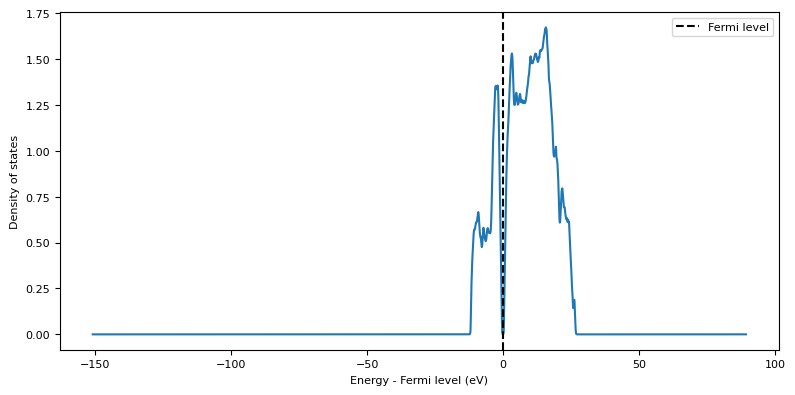

In [53]:
silicon = bulk("Si", crystalstructure="diamond", a=5.43)
dos_calculator = mlipstudio.create_calculator(
    "PET-MAD-DOS",
    device="cpu",
    version="latest",
)
dos_task = mlipstudio.BandGapDOSTask()
dos_result = dos_task.calculate(silicon, dos_calculator)

print(f"Band gap: {dos_result.band_gap_eV:.6f} eV")
print(f"Fermi level: {dos_result.fermi_level_eV:.6f} eV")
print(f"DOS points: {len(dos_result.density_of_states)}")

plt.figure(figsize=(8, 4))
plt.plot(
    dos_result.energies_relative_to_fermi_eV,
    dos_result.density_of_states,
)
plt.axvline(0.0, color="black", linestyle="--", label="Fermi level")
plt.xlabel("Energy - Fermi level (eV)")
plt.ylabel("Density of states")
plt.legend()
plt.tight_layout()
plt.show()

del dos_calculator
release_unused_resources()

## 11. Batch HOMO-LUMO prediction

The batch wrapper preserves input order and records individual failures instead of losing the entire batch.

In [54]:
qm9_calculator = mlipstudio.create_calculator("QM9-Gap", device=DEVICE)
gap_batch = mlipstudio.BatchHOMOLUMOGapTask().calculate(
    [molecule("CH4"), molecule("H2O")], qm9_calculator
)
for item in gap_batch.successful_items:
    print(item.label, item.result.gap_eV)
del qm9_calculator
release_unused_resources()

CH4_1 13.629583358764648
H2O_2 9.849166870117188


## 12. Optimizer comparison on taxol: Lindh Hessian LBFGS vs LBFGS

Taxol (paclitaxel, C45H49NO15, 110 atoms) is a large, flexible drug molecule and a good test for geometry optimizers. This section optimizes the `Taxol.xyz` sample structure shipped with the repository twice with the same MACE POLAR 1 S calculator: once with ASE's standard `LBFGS` and once with MLIP Studio's `Lindh Hessian LBFGS`.

`Lindh Hessian LBFGS` preconditions LBFGS with Lindh's model Hessian, which is built from the bond, angle and dihedral terms of the current geometry (Lindh et al., *Chem. Phys. Lett.* 241, 423 (1995)). It needs no Hessian from the MLIP, so it works with any calculator, but only for fixed-cell optimizations.

Both runs use the API's default convergence criterion, `fmax=0.01` eV/Å, with the step limit raised to 1000 so that both can converge. Expect a few minutes on a T4 GPU. The final energies may differ slightly, because a flexible molecule can relax into different nearby local minima. Exact step counts and timings also vary a little between runs and GPUs, because float32 GPU calculations are not bit-for-bit reproducible.

In [55]:
import io

from ase.io import read

taxol = read(REPO_DIR / "sample_structures" / "Taxol.xyz")
print(taxol.get_chemical_formula(), "-", len(taxol), "atoms")


def parse_optimizer_log(text):
    """Step, energy (eV) and maximum force (eV/Angstrom) from an ASE optimizer log."""
    rows = []
    for line in text.splitlines():
        parts = line.split()
        if parts and parts[0].endswith(":"):
            rows.append((int(parts[1]), float(parts[-2]), float(parts[-1])))
    return pd.DataFrame(rows, columns=["step", "energy_eV", "max_force_eV_per_A"])


optimizer_calculator = mlipstudio.create_calculator("MACE POLAR 1 S", device=DEVICE)
optimizer_runs = {}
for optimizer_name in ("LBFGS", "Lindh Hessian LBFGS"):
    optimizer_log = io.StringIO()
    optimizer_result = mlipstudio.OptimizationTask(
        optimizer=optimizer_name,
        fmax=0.01,
        steps=1000,
        logfile=optimizer_log,
    ).calculate(taxol, optimizer_calculator)
    optimizer_runs[optimizer_name] = (
        optimizer_result,
        parse_optimizer_log(optimizer_log.getvalue()),
    )
    print(f"{optimizer_name}: {optimizer_result.steps} steps, {optimizer_result.runtime_seconds:.1f} s")

del optimizer_calculator
release_unused_resources()

C45H49NO15 - 110 atoms
Using Materials Project MACE for MACECalculator with /root/.cache/mace/MACEPOLAR1Smodel
Using float32 for MACECalculator, which is faster but less accurate. Recommended for MD. Use float64 for geometry optimization.


/usr/local/lib/python3.12/dist-packages/mace/calculators/mace.py:207: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)


LBFGS: 685 steps, 102.1 s
Lindh Hessian LBFGS: 194 steps, 45.1 s


,optimizer,converged,steps,final_energy_eV,final_max_force_eV_per_A,runtime_s
0,LBFGS,True,685,-79662.101562,0.009501,102.065634
1,Lindh Hessian LBFGS,True,194,-79662.203125,0.009321,45.062986


LBFGS needed 3.5x as many steps and 2.3x as much time as Lindh Hessian LBFGS.


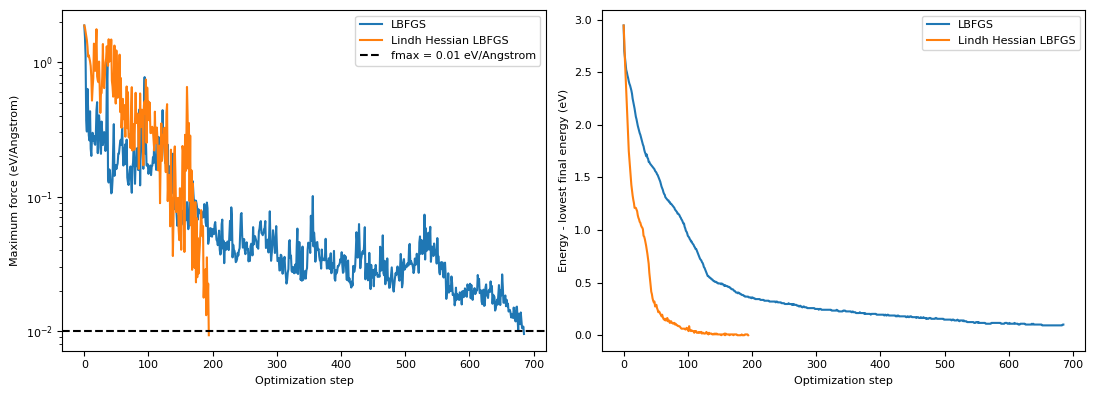

In [56]:
optimizer_summary = pd.DataFrame(
    {
        "optimizer": name,
        "converged": result.converged,
        "steps": result.steps,
        "final_energy_eV": result.energy,
        "final_max_force_eV_per_A": result.atomic_max_force,
        "runtime_s": result.runtime_seconds,
    }
    for name, (result, _) in optimizer_runs.items()
)
display(optimizer_summary)

lbfgs_result = optimizer_runs["LBFGS"][0]
lindh_result = optimizer_runs["Lindh Hessian LBFGS"][0]
print(
    f"LBFGS needed {lbfgs_result.steps / lindh_result.steps:.1f}x as many steps and "
    f"{lbfgs_result.runtime_seconds / lindh_result.runtime_seconds:.1f}x as much time "
    "as Lindh Hessian LBFGS."
)

lowest_energy = min(result.energy for result, _ in optimizer_runs.values())
fig, (force_ax, energy_ax) = plt.subplots(1, 2, figsize=(11, 4))
for name, (_, log_table) in optimizer_runs.items():
    force_ax.semilogy(log_table.step, log_table.max_force_eV_per_A, label=name)
    energy_ax.plot(log_table.step, log_table.energy_eV - lowest_energy, label=name)
force_ax.axhline(0.01, color="black", linestyle="--", label="fmax = 0.01 eV/Angstrom")
force_ax.set_xlabel("Optimization step")
force_ax.set_ylabel("Maximum force (eV/Angstrom)")
force_ax.legend()
energy_ax.set_xlabel("Optimization step")
energy_ax.set_ylabel("Energy - lowest final energy (eV)")
energy_ax.legend()
plt.tight_layout()
plt.show()

## 13. Where to go next

All task objects follow the same pattern: configure the task, then call `task.calculate(atoms, calculator)`. Results contain raw numerical arrays/scalars in documented ASE units and calculator-free copies of structures.

This notebook covered:

- `SinglePointTask`
- `OptimizationTask`, including a Lindh Hessian LBFGS vs LBFGS comparison on taxol
- `AtomizationCohesiveEnergyTask` for both cohesive and atomization energy
- `HOMOLUMOGapTask`
- `DipoleMomentTask` with MACE-POLAR and AIMNet2 models
- `SpinDeterminationTask`
- `BandGapDOSTask`
- `MACEHessianTask`
- `VibrationalModeTask`
- `EquationOfStateTask`
- `ModelConsensusTask`
- batch single-point, HOMO-LUMO, and atomization/cohesive tasks

Use `mlipstudio.list_models()` and `mlipstudio.get_model_spec(name)` for programmatic discovery. Reuse a loaded calculator sequentially when possible, but create independent calculators for parallel workers or future NEB image calculations.